# Setup

In [1]:
import os
import pickle

import numpy as np
import pandas as pd
import scipy.cluster.hierarchy as hc
import scipy.spatial as sp

import matplotlib
import matplotlib.colors as mcolors
import matplotlib.patches as patches
from matplotlib import pyplot as plt
import seaborn as sns
import plotly.express as px

from tqdm.notebook import tqdm

In [2]:
from kneebow.rotor import Rotor

In [3]:
RAW_GENOMES = '/mnt/craig/pan_phylon/S_aureus/raw/genomes/'
MASH_GENOMES = '/mnt/craig/pan_phylon/S_aureus/raw/mash_genomes/'

In [4]:
UNIFIED_METADATA = '/mnt/craig/pan_phylon/S_pyogenes/metadata/unified_genome_metadata.csv'

In [5]:
scrubbed_metadata = pd.read_csv(UNIFIED_METADATA, index_col=0, dtype='object')

# Ensure genome id is a str
scrubbed_metadata['genome_id'] = scrubbed_metadata['genome_id'].astype('str')

display(
    scrubbed_metadata.shape,
    scrubbed_metadata.head()
)

(427, 126)

,source,genome_id,genome_name,organism_name,taxon_id,strain,# ambiguous bases,# genomes,0,1,...,sequencing_platform,sequencing_status,serovar,species,sporulation,taxon_lineage_ids,taxon_lineage_names,temperature_range,total_genes,type_strain
assembly_accession_resolved,,,,,,,,,,,,,,,,,,,,,
GCF_900636725.1,NCBI,GCF_900636725.1,NaN,Streptococcus pyogenes,1314,NCTC8302,0.0,30.0,2.0,667.0,...,PacBio,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1843.0,NaN
GCF_041430875.1,NCBI,GCF_041430875.1,NaN,Streptococcus pyogenes,1314,Isolate 23,0.0,30.0,2.0,674.0,...,"Illumina NextSeq 500, Nanopore GridION",NaN,NaN,NaN,NaN,NaN,NaN,NaN,1923.0,NaN
GCF_041447185.1,NCBI,GCF_041447185.1,NaN,Streptococcus pyogenes,1314,Isolate 32,0.0,240.0,0.0,524.0,...,"Illumina NextSeq 500, Nanopore GridION",NaN,NaN,NaN,NaN,NaN,NaN,NaN,1849.0,NaN
GCF_041431055.1,NCBI,GCF_041431055.1,NaN,Streptococcus pyogenes,1314,Isolate 1,0.0,30.0,2.0,674.0,...,"Illumina NextSeq 500, Nanopore GridION",NaN,NaN,NaN,NaN,NaN,NaN,NaN,1677.0,NaN
GCF_001678885.1,BV-BRC,1314.375,Streptococcus pyogenes strain STAB09014,NaN,1314,STAB09014,NaN,NaN,NaN,NaN,...,Illumina,Complete,NaN,Streptococcus pyogenes,NaN,131567;2;1783272;1239;91061;186826;1300;1301;1314,cellular organisms;Bacteria;Terrabacteria grou...,NaN,NaN,NaN


# Mash filtration and clustering

In [6]:
names = [
    'genome1',
    'genome2',
    'mash_distance',
    'p_value',
    'matching_hashes'
]

df_mash = pd.read_csv('/mnt/craig/pan_phylon/S_pyogenes/raw/S_pyogenes_distances.tsv', sep='\t', names=names)
df_mash['genome1'] = df_mash['genome1'].apply(lambda x: x.split('/')[-1].split('.fna')[0])
df_mash['genome2'] = df_mash['genome2'].apply(lambda x: x.split('/')[-1].split('.fna')[0])

df_mash

,genome1,genome2,mash_distance,p_value,matching_hashes
0,1010840.4,1010840.4,0.000000,0,1000/1000
1,1048264.3,1010840.4,0.013016,0,614/1000
2,1150773.3,1010840.4,0.012447,0,626/1000
3,1150773.4,1010840.4,0.012447,0,626/1000
4,1235829.3,1010840.4,0.010741,0,664/1000
...,...,...,...,...,...
161599,GCF_055378755.1,GCF_900636725.1,0.010569,0,668/1000
161600,GCF_900608505.1,GCF_900636725.1,0.012353,0,628/1000
161601,GCF_900636425.1,GCF_900636725.1,0.012493,0,625/1000
161602,GCF_900636485.1,GCF_900636725.1,0.011001,0,658/1000


In [7]:
df_mash_square = df_mash.pivot(index='genome1', columns='genome2', values='mash_distance')

df_mash_square

genome2,1010840.4,1048264.3,1150773.3,1150773.4,1235829.3,1314.1001,1314.1002,1314.1003,1314.1004,1314.1005,...,GCF_055362005.1,GCF_055362025.1,GCF_055362045.1,GCF_055362065.1,GCF_055362085.1,GCF_055378755.1,GCF_900608505.1,GCF_900636425.1,GCF_900636485.1,GCF_900636725.1
genome1,,,,,,,,,,,,,,,,,,,,,
1010840.4,0.000000,0.013016,0.012447,0.012447,0.010741,0.011938,0.012635,0.010272,0.011088,0.009126,...,0.011132,0.010914,0.011621,0.012447,0.010697,0.011442,0.011442,0.010062,0.013404,0.012400
1048264.3,0.013016,0.000000,0.014252,0.014252,0.012353,0.013257,0.014767,0.014252,0.013306,0.012214,...,0.011576,0.002162,0.002298,0.014559,0.011397,0.012729,0.012729,0.012824,0.015347,0.014252
1150773.3,0.012447,0.014252,0.000000,0.000000,0.012682,0.013600,0.013650,0.013160,0.013551,0.011666,...,0.012872,0.012493,0.013209,0.012968,0.012920,0.010612,0.012400,0.012540,0.011001,0.000119
1150773.4,0.012447,0.014252,0.000000,0.000000,0.012682,0.013600,0.013650,0.013160,0.013551,0.011666,...,0.012872,0.012493,0.013209,0.012968,0.012920,0.010612,0.012400,0.012540,0.011001,0.000119
1235829.3,0.010741,0.012353,0.012682,0.012682,0.000000,0.012122,0.013799,0.011938,0.012260,0.010870,...,0.011487,0.010314,0.011353,0.012682,0.011044,0.011666,0.000656,0.011264,0.014508,0.012729
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GCF_055378755.1,0.011442,0.012729,0.010612,0.010612,0.011666,0.013064,0.012824,0.010062,0.011001,0.009166,...,0.011487,0.011132,0.011711,0.013306,0.011353,0.000000,0.011984,0.009086,0.011756,0.010569
GCF_900608505.1,0.011442,0.012729,0.012400,0.012400,0.000656,0.012307,0.014354,0.012400,0.012729,0.011487,...,0.011176,0.011001,0.011487,0.012777,0.011711,0.011984,0.000000,0.011802,0.014923,0.012353
GCF_900636425.1,0.010062,0.012824,0.012540,0.012540,0.011264,0.012214,0.012920,0.011132,0.010870,0.007088,...,0.009979,0.010957,0.011487,0.012635,0.009855,0.009086,0.011802,0.000000,0.013749,0.012493


## Generate corressponding pearson-correlation matrix (& distance matrix)

In [8]:
df_mash_corr = df_mash_square.corr()
df_mash_corr_dist = 1 - df_mash_corr
df_mash_corr_dist

df_mash_corr_dist.to_csv('/mnt/craig/pan_phylon/S_pyogenes/processed/df_mash_corr_dist.csv')

display(
    df_mash_corr_dist.shape,
    df_mash_corr_dist.head()
)

(402, 402)

genome2,1010840.4,1048264.3,1150773.3,1150773.4,1235829.3,1314.1001,1314.1002,1314.1003,1314.1004,1314.1005,...,GCF_055362005.1,GCF_055362025.1,GCF_055362045.1,GCF_055362065.1,GCF_055362085.1,GCF_055378755.1,GCF_900608505.1,GCF_900636425.1,GCF_900636485.1,GCF_900636725.1
genome2,,,,,,,,,,,,,,,,,,,,,
1010840.4,0.000000,0.922523,0.996695,0.996695,0.670142,0.765863,0.506632,0.437584,0.543051,0.443800,...,0.797035,0.839620,0.943035,1.141537,0.742511,0.833109,0.702568,0.492606,0.974989,0.994551
1048264.3,0.922523,0.000000,1.156718,1.156718,0.948407,0.926902,1.034298,1.063246,0.907612,0.933191,...,0.783461,0.025103,0.026476,1.196125,0.787611,0.988772,0.955044,0.904633,1.136016,1.155229
1150773.3,0.996695,1.156718,0.000000,0.000000,1.076021,1.184042,0.905406,0.913629,1.020700,0.830965,...,1.099058,1.127386,1.122138,0.983612,1.108579,0.613360,1.065896,0.782390,0.349992,0.000184
1150773.4,0.996695,1.156718,0.000000,0.000000,1.076021,1.184042,0.905406,0.913629,1.020700,0.830965,...,1.099058,1.127386,1.122138,0.983612,1.108579,0.613360,1.065896,0.782390,0.349992,0.000184
1235829.3,0.670142,0.948407,1.076021,1.076021,0.000000,0.971990,0.922776,0.716487,0.909851,0.926595,...,1.074449,0.845224,0.969646,1.158075,1.012297,0.982427,0.003210,0.884700,1.180467,1.079750


## Filter strains by Mash distance

- __Criteria 1:__ Mash value of 0.05 (soft-limit on bacterial species delineation) ✅
- __Criteria 2:__ Any clear outliers ✅


<Axes: ylabel='Count'>

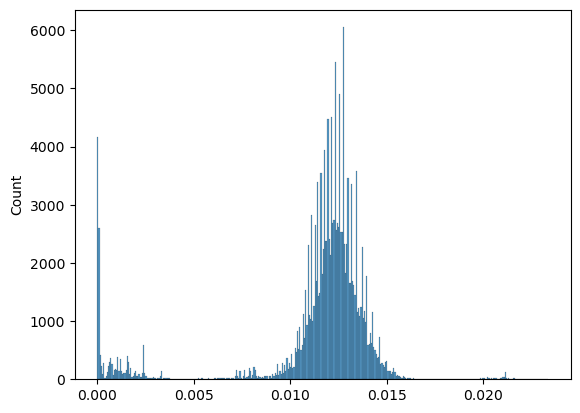

In [9]:
sns.histplot(df_mash_square.values.flatten())

### Find your Reference/Representative Strain ID (for filtration)

In [10]:
repr_strain = '1314.739' # Add in your reference strain
scrubbed_metadata.set_index('genome_id').loc[repr_strain]

source                                                            BV-BRC
genome_name                      Streptococcus pyogenes strain NCTC12064
organism_name                                                        NaN
taxon_id                                                            1314
strain                                                         NCTC12064
                                             ...                        
taxon_lineage_ids      131567;2;1783272;1239;91061;186826;1300;1301;1314
taxon_lineage_names    cellular organisms;Bacteria;Terrabacteria grou...
temperature_range                                                    NaN
total_genes                                                          NaN
type_strain                                                          NaN
Name: 1314.739, Length: 125, dtype: object

In [11]:
# This cutoff is dependent on the data you see above
# Past studies have gone down as low as 98.5th percentile
# but 99th or 99.9th percentiles are also acceptable
# if it looks too low, just use 0.05 instead

candidate_cutoff_985 = np.quantile(df_mash_square.loc[repr_strain], 0.985)
candidate_cutoff_99 = np.quantile(df_mash_square.loc[repr_strain], 0.99)
candidate_cutoff_999 = np.quantile(df_mash_square.loc[repr_strain], 0.999)

print([candidate_cutoff_985, candidate_cutoff_99, candidate_cutoff_999])

[0.013794145000000004, 0.0137986, 0.01774478529999995]


In [12]:
mash_cutoff = 0.05 # our chosen mash threshold
mash_cutoff

0.05

In [13]:
# Filtering strains by our chosen mash_cutoff threshold
cond = df_mash_square.loc[repr_strain] < mash_cutoff
good_strains = df_mash_square.loc[repr_strain][cond].index

df_mash_square = df_mash_square.loc[good_strains, good_strains]
df_mash_corr = df_mash_corr.loc[good_strains, good_strains]
df_mash_corr_dist = df_mash_square.loc[good_strains, good_strains]

df_mash_corr_dist.shape

(402, 402)

In [14]:
# Updating scrubbed strain data files
mash_scrubbed_metadata = scrubbed_metadata.set_index('genome_id').loc[sorted(df_mash_square.index)].reset_index()


display(
    mash_scrubbed_metadata.shape,
    mash_scrubbed_metadata.head()
)

(402, 126)

,genome_id,source,genome_name,organism_name,taxon_id,strain,# ambiguous bases,# genomes,0,1,...,sequencing_platform,sequencing_status,serovar,species,sporulation,taxon_lineage_ids,taxon_lineage_names,temperature_range,total_genes,type_strain
0,1010840.4,BV-BRC,Streptococcus pyogenes MGAS1882,Streptococcus pyogenes MGAS1882,1010840,MGAS1882,NaN,NaN,NaN,NaN,...,454; Illumina,Complete,NaN,Streptococcus pyogenes,NaN,131567;2;1783272;1239;91061;186826;1300;1301;1...,cellular organisms;Bacteria;Terrabacteria grou...,NaN,NaN,NaN
1,1048264.3,BV-BRC,Streptococcus pyogenes HKU QMH11M0907901,NaN,1048264,HKU QMH11M0907901,NaN,NaN,NaN,NaN,...,454 GS FLX titanium,Complete,NaN,Streptococcus pyogenes,NaN,131567;2;1783272;1239;91061;186826;1300;1301;1...,cellular organisms;Bacteria;Terrabacteria grou...,NaN,NaN,NaN
2,1150773.3,BV-BRC,Streptococcus pyogenes JRS4,NaN,1150773,JRS4,NaN,NaN,NaN,NaN,...,454; Illumina,Complete,serovar emm6,Streptococcus pyogenes,NaN,131567;2;1783272;1239;91061;186826;1300;1301;1...,cellular organisms;Bacteria;Terrabacteria grou...,NaN,NaN,NaN
3,1150773.4,BV-BRC,Streptococcus pyogenes JRS4,NaN,1150773,JRS4,NaN,NaN,NaN,NaN,...,Sanger; Roche 454,Complete,NaN,Streptococcus pyogenes,NaN,131567;2;1783272;1239;91061;186826;1300;1301;1...,cellular organisms;Bacteria;Terrabacteria grou...,NaN,NaN,NaN
4,1235829.3,BV-BRC,Streptococcus pyogenes A20,Streptococcus pyogenes A20,1235829,A20,NaN,NaN,NaN,NaN,...,NaN,Complete,NaN,Streptococcus pyogenes,NaN,131567;2;1783272;1239;91061;186826;1300;1301;1...,cellular organisms;Bacteria;Terrabacteria grou...,NaN,NaN,NaN


## Useful functions for later analysis

In [15]:
def cluster_corr_dist(df_mash_corr_dist, thresh=0.1, method='ward', metric='euclidean'):
    '''
    Hierarchically Mash-based pairwise-pearson-distance matrix
    '''
    link = hc.linkage(sp.distance.squareform(df_mash_corr_dist), method=method, metric=metric)
    dist = sp.distance.squareform(df_mash_corr_dist)
    
    clst = pd.DataFrame(index=df_mash_corr_dist.index)
    clst['cluster'] = hc.fcluster(link, thresh * dist.max(), 'distance')
    
    return link, dist, clst


def remove_bad_strains(df_mash_scd, bad_strains_list):
    good_strains_list = sorted(set(df_mash_scd.index) - set(bad_strains_list))
    
    return df_mash_scd.loc[good_strains_list, good_strains_list]


# Sensitivity analysis to pick the threshold (for E. coli we use 0.1)
# We pick the threshold where the curve just starts to bottom out
def sensitivity_analysis(df_mash_corr_dist_complete):
    x = list(np.logspace(-3, -1, 10)) + list(np.linspace(0.1, 1, 19))
    
    def num_uniq_clusters(thresh):
        link = hc.linkage(sp.distance.squareform(df_mash_corr_dist_complete), method='ward', metric='euclidean')
        dist = sp.distance.squareform(df_mash_corr_dist_complete)
        
        clst = pd.DataFrame(index=df_mash_corr_dist_complete.index)
        clst['cluster'] = hc.fcluster(link, thresh * dist.max(), 'distance')
        
        return len(clst.cluster.unique())
    
    tmp = pd.DataFrame()
    tmp['threshold'] = pd.Series(x)
    tmp['num_clusters'] = pd.Series(x).apply(num_uniq_clusters)
    
    # Find which value the elbow corresponds to
    df_temp = tmp.sort_values(by='num_clusters', ascending=True).reset_index(drop=True)
    
    # transform input into form necessary for package
    results_itr = zip(list(df_temp.index), list(df_temp.num_clusters))
    data = list(results_itr)
    
    rotor = Rotor()
    rotor.fit_rotate(data)
    elbow_idx = rotor.get_elbow_index()
    contamination_cutoff = df_temp['num_clusters'][elbow_idx]
    
    # Grab elbow threshold
    cond = tmp['num_clusters'] == df_temp['num_clusters'][elbow_idx]
    elbow_threshold = tmp[cond]['threshold'].iloc[0]
    
    return tmp, df_temp, elbow_idx, elbow_threshold



## Find threshold for Mash clustering

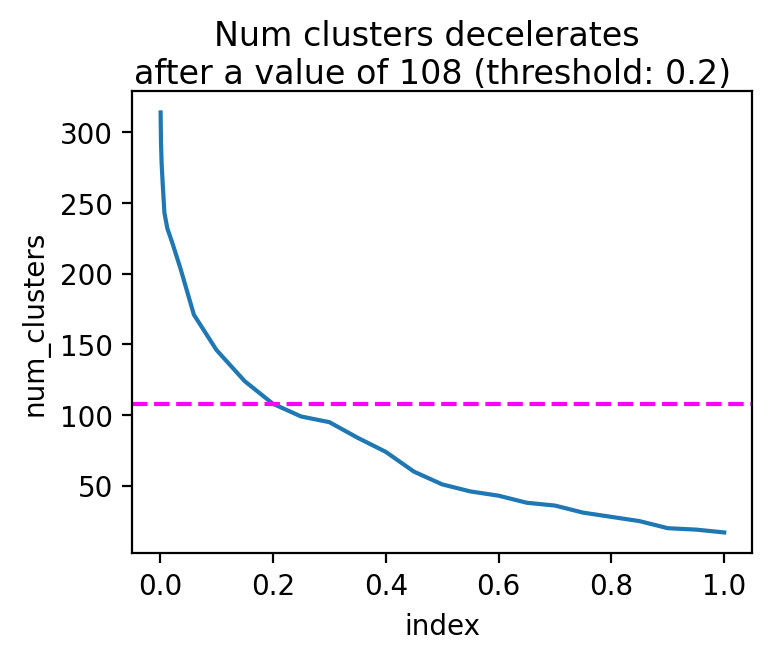

In [16]:
# Initial sensitivity analysis (gives min val to consider)
tmp, df_temp, elbow_idx, elbow_threshold = sensitivity_analysis(df_mash_corr_dist)

# Plot (tells us to pick something > 0.25)
plt.rcParams["figure.dpi"] = 200
fig, axs = plt.subplots(figsize=(4,3),)
axs.plot(tmp['threshold'], tmp['num_clusters'])
plt.axhline(y=df_temp['num_clusters'][elbow_idx], c="#ff00ff", linestyle='--')
axs.set_ylabel('num_clusters')
axs.set_xlabel('index')
fig.suptitle(
    f"Num clusters decelerates \nafter a value of {df_temp['num_clusters'][elbow_idx]} (threshold: {elbow_threshold})",
    y=1
)
plt.show()

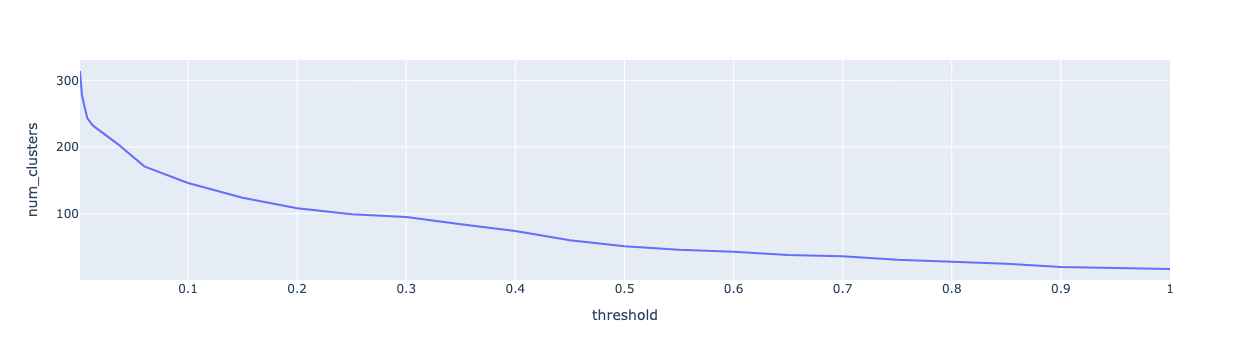

In [17]:
px.line(tmp, x='threshold', y='num_clusters') # interactive plot

## Plot initial clustermap of Mash values

In [18]:
elbow_threshold = elbow_threshold+0.1 # "round" up

link_init, dist_init, clst_init = cluster_corr_dist(df_mash_corr_dist, thresh=elbow_threshold)

# Color each cluster
cm = matplotlib.colormaps.get_cmap('tab20')
cmb = matplotlib.colormaps.get_cmap('tab20b')
cmc = matplotlib.colormaps.get_cmap('tab20c')
clr = dict(zip(sorted(clst_init.cluster.unique()), cm.colors + cmb.colors + cmc.colors))
clst_init['color'] = clst_init.cluster.map(clr)

print('Number of colors: ', len(clr))
print('Number of clusters', len(clst_init.cluster.unique()))

Number of colors:  60
Number of clusters 95


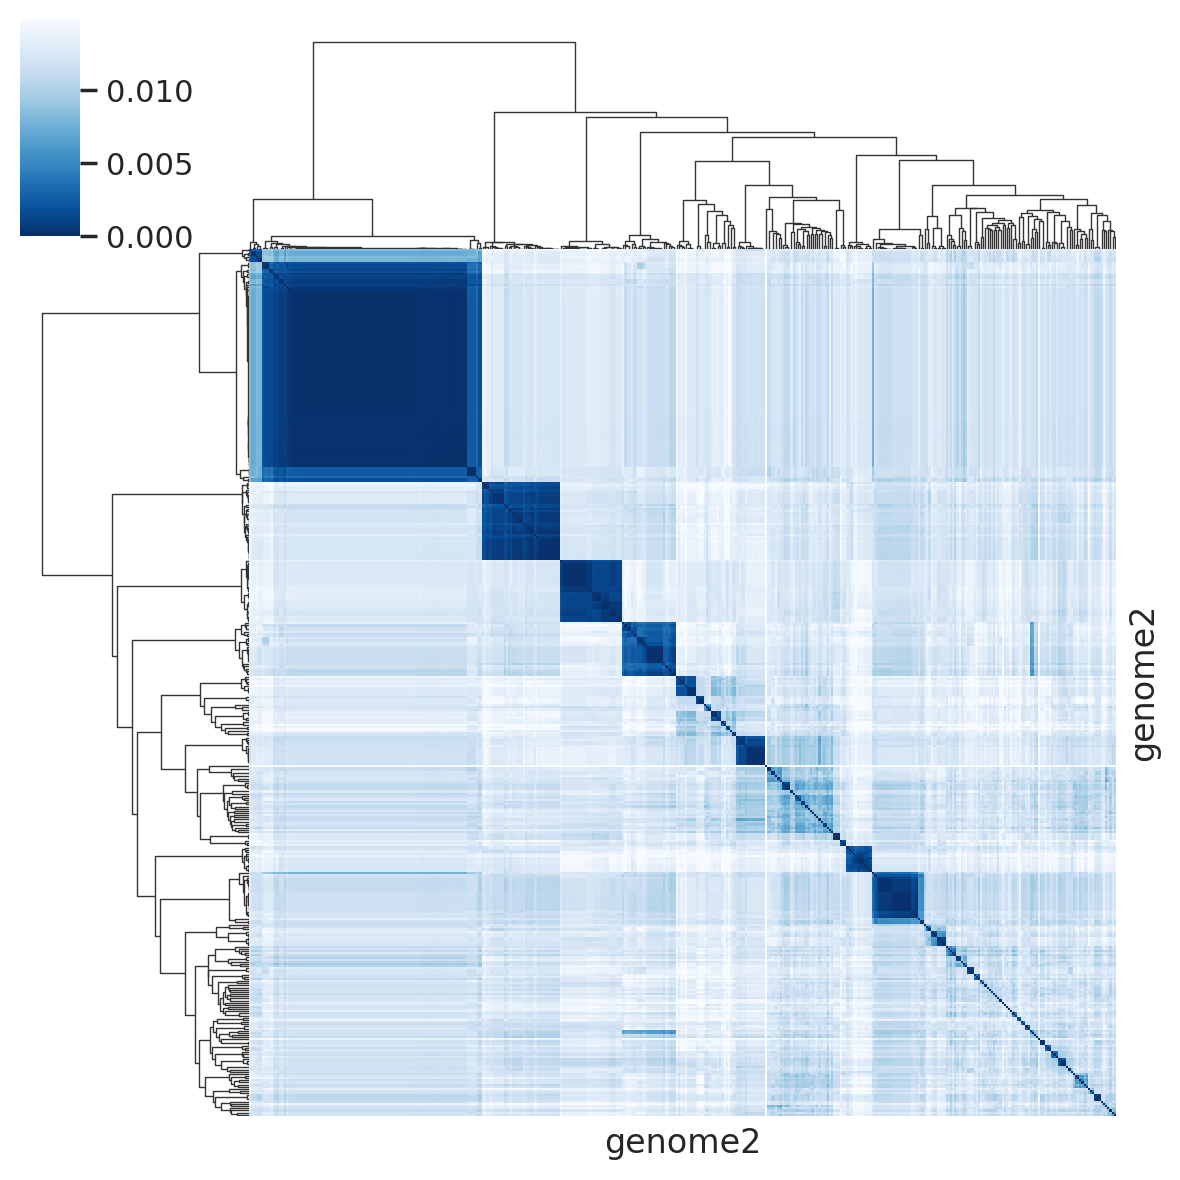

In [19]:
size = 6

legend_TN = [patches.Patch(color=c, label=l) for l,c in clr.items()]

sns.set(rc={'figure.facecolor':'white'})
g = sns.clustermap(
    df_mash_square,
    figsize=(size,size),
    row_linkage=link_init,
    col_linkage=link_init,
    #col_colors=clst_init.color,
    yticklabels=False,
    xticklabels=False,
    cmap='Blues_r',
    robust=True
)

#l2=g.ax_heatmap.legend(loc='upper left', bbox_to_anchor=(1.01,0.9), handles=legend_TN,frameon=True)
#l2.set_title(title='Clusters',prop={'size':10})

## Filter out small clusters

Typically with < 5 members but this depends on the distribution of the cluster sizes. Look at the histogram to determine this

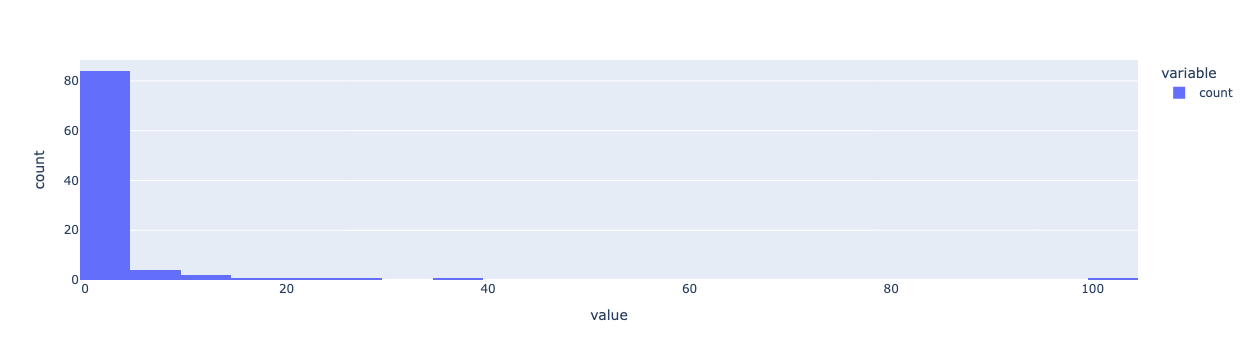

In [20]:
px.histogram(clst_init.cluster.value_counts(), nbins=50)

In [21]:
small_clst_limit = 5 # Our choice based on the histogram above

In [22]:
bad_clusters = clst_init.cluster.value_counts()[clst_init.cluster.value_counts() < small_clst_limit]
bad_clusters

cluster
46    4
8     4
47    4
79    4
22    4
     ..
10    1
20    1
74    1
48    1
59    1
Name: count, Length: 84, dtype: int64

In [23]:
bad_genomes_list = []

for genome in df_mash_square.index:
    cluster = clst_init.loc[genome, 'cluster']
    if cluster in bad_clusters:
        bad_genomes_list.append(genome)

# Update filtration
df_mash_square_filt = remove_bad_strains(df_mash_square, bad_genomes_list)
df_mash_corr_filt = remove_bad_strains(df_mash_corr, bad_genomes_list)
df_mash_corr_dist_filt = remove_bad_strains(df_mash_corr_dist, bad_genomes_list)

## Keep filtering until robust clusters show up

In [24]:
iteration = 1
prev = 0
curr = len(clst_init.cluster.unique())

while(np.abs(prev - curr) > 0 ):
    print(f'iteration {iteration}...{curr}')
    
    # Cluster
    link, dist, clst = cluster_corr_dist(df_mash_corr_dist_filt, thresh=elbow_threshold)
    
    # Color each cluster
    cm = matplotlib.colormaps.get_cmap('tab20')
    cmb = matplotlib.colormaps.get_cmap('tab20b')
    cmc = matplotlib.colormaps.get_cmap('tab20c')
    clr = dict(zip(sorted(clst.cluster.unique()), cm.colors + cmb.colors + cmc.colors))
    clst['color'] = clst.cluster.map(clr)
    
    # Increment
    prev = curr
    curr = len(clst.cluster.unique())
    
    # Define bad clusters
    bad_clusters = clst.cluster.value_counts()[clst.cluster.value_counts() < small_clst_limit]
    
    # Remove bad genomes
    bad_genomes_list = []
    for genome in df_mash_square_filt.index:
        cluster = clst.loc[genome, 'cluster']
        if cluster in bad_clusters:
            bad_genomes_list.append(genome)
    
    # Update filtration
    df_mash_square_filt = remove_bad_strains(df_mash_square_filt, bad_genomes_list)
    df_mash_corr_filt = remove_bad_strains(df_mash_corr_filt, bad_genomes_list)
    df_mash_corr_dist_filt = remove_bad_strains(df_mash_corr_dist_filt, bad_genomes_list)
    
    # Increment
    iteration +=1

iteration 1...95
iteration 2...13
iteration 3...12


In [25]:
df_mash_square_filt.shape # Current shape after filtering for only robust mash clusters

(254, 254)

In [26]:
link_filt, dist_filt, clst_filt = cluster_corr_dist(df_mash_corr_dist_filt, thresh=elbow_threshold)

# Color each cluster
cm = matplotlib.colormaps.get_cmap('tab20')
cmb = matplotlib.colormaps.get_cmap('tab20b')
cmc = matplotlib.colormaps.get_cmap('tab20c')
clr = dict(zip(sorted(clst_filt.cluster.unique()), cm.colors + cmb.colors + cmc.colors))
clst_filt['color'] = clst_filt.cluster.map(clr)

print('Number of colors: ', len(clr))
print('Number of clusters', len(clst_filt.cluster.unique()))

Number of colors:  12
Number of clusters 12


In [27]:
assert clst_filt.cluster.value_counts().min() >= small_clst_limit

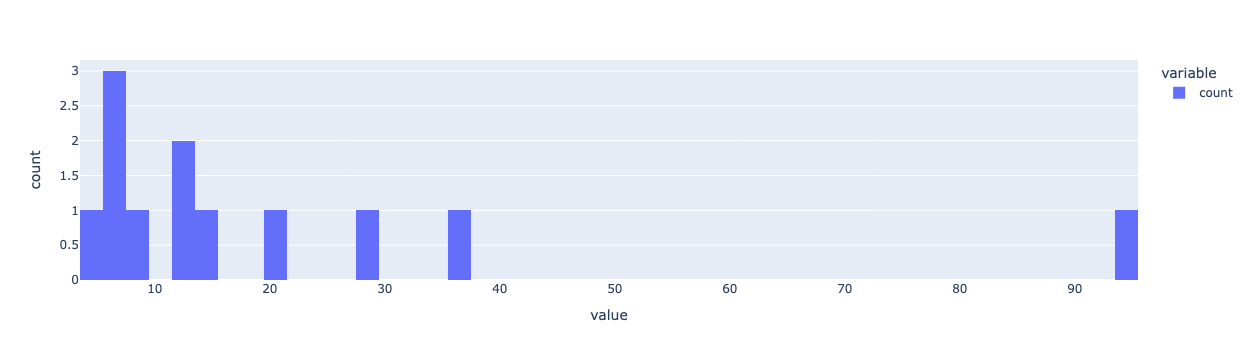

In [28]:
px.histogram(clst_filt.cluster.value_counts(), nbins=50)

# Plot filtered Mash clustermap


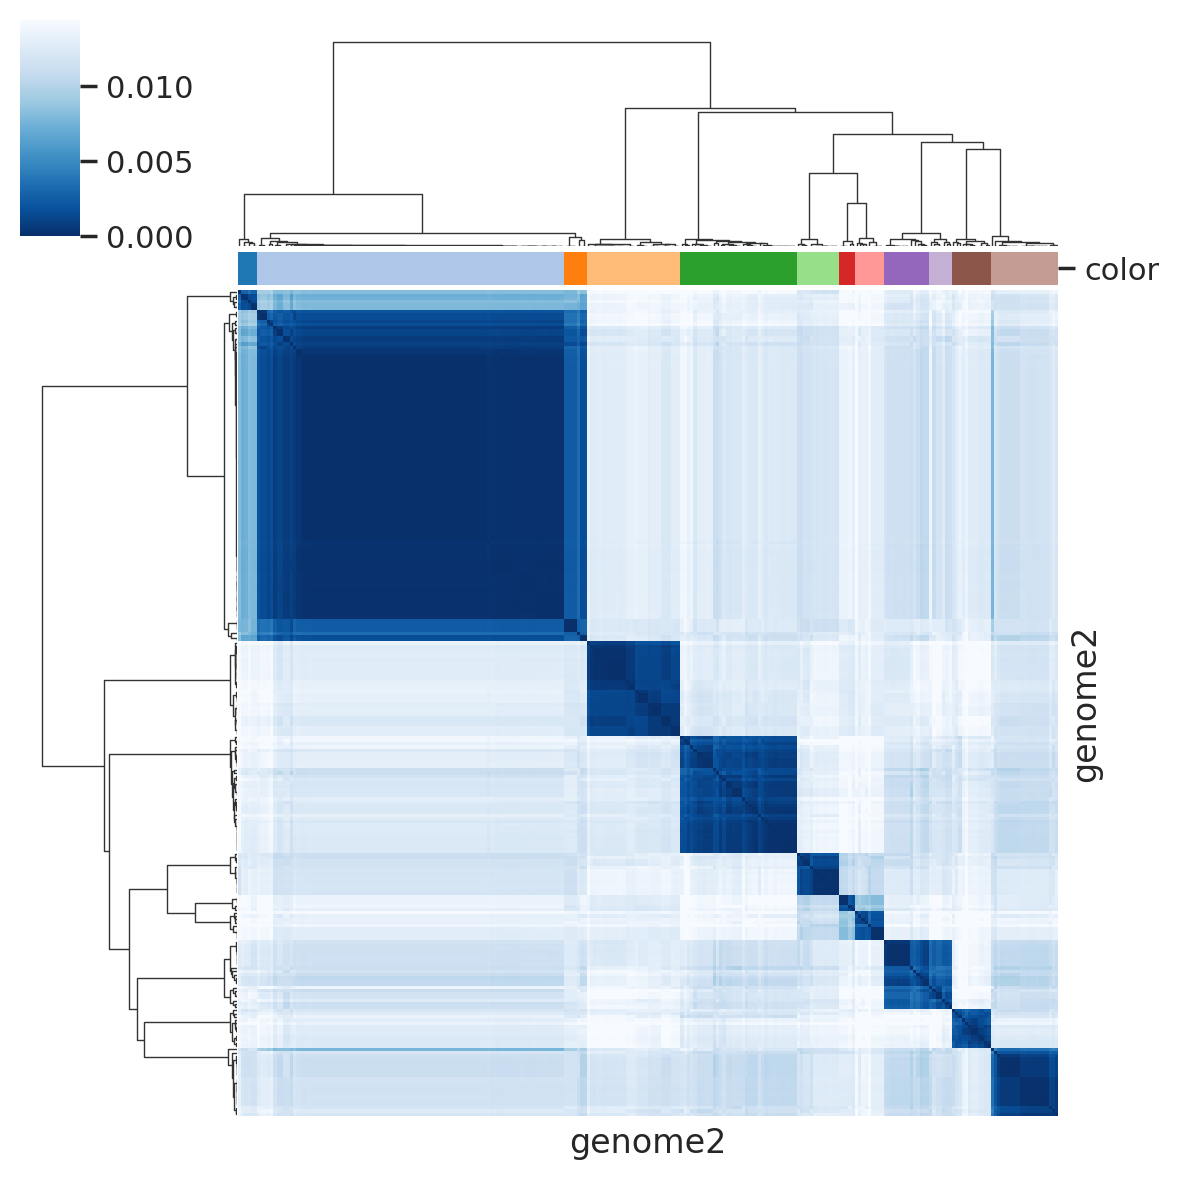

In [29]:
size = 6

legend_TN = [patches.Patch(color=c, label=l) for l,c in clr.items()]

sns.set(rc={'figure.facecolor':'white'})
g = sns.clustermap(
    df_mash_square_filt,
    figsize=(size,size),
    row_linkage=link_filt,
    col_linkage=link_filt,
    col_colors=clst_filt.color,
    yticklabels=False,
    xticklabels=False,
    cmap='Blues_r',
    robust=True
)

#l2=g.ax_heatmap.legend(loc='upper left', bbox_to_anchor=(1.05,1), handles=legend_TN,frameon=True)
#l2.set_title(title='Clusters',prop={'size':10})

# Plot full Mash clustermap with filtered clusters

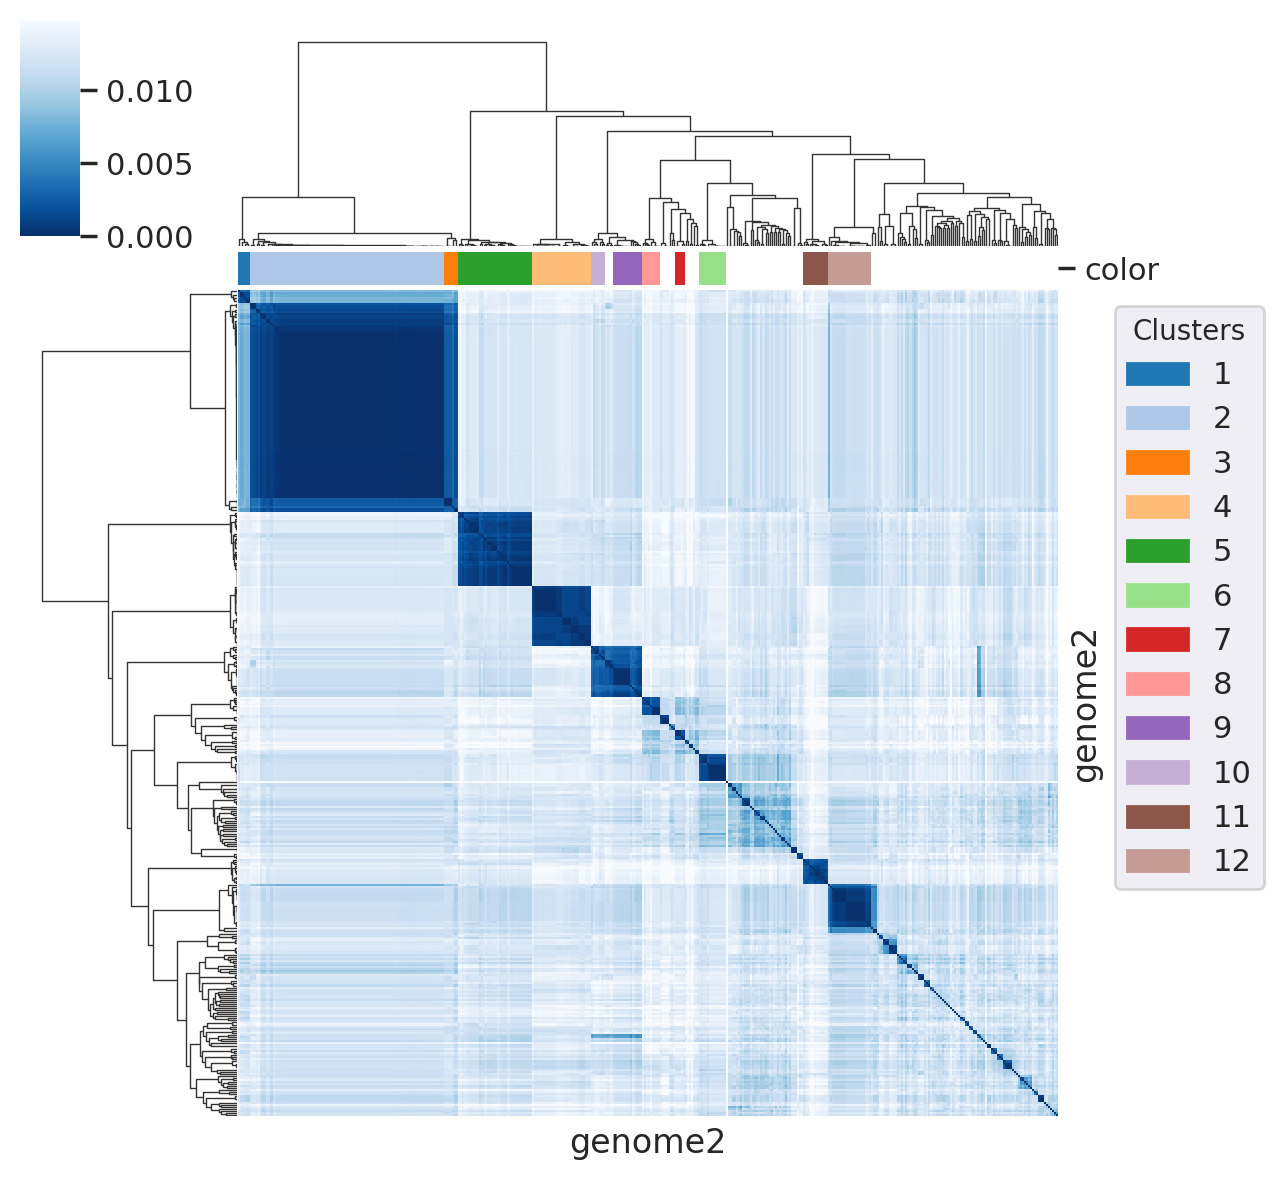

In [30]:
size = 6

legend_TN = [patches.Patch(color=c, label=l) for l,c in clr.items()]

sns.set(rc={'figure.facecolor':'white'})
g = sns.clustermap(
    df_mash_square,
    figsize=(size,size),
    row_linkage=link_init,
    col_linkage=link_init,
    col_colors=clst_filt.color,
    yticklabels=False,
    xticklabels=False,
    cmap='Blues_r',
    robust=True
)

l2=g.ax_heatmap.legend(loc='upper left', bbox_to_anchor=(1.05,1), handles=legend_TN,frameon=True)
l2.set_title(title='Clusters',prop={'size':10})

In [31]:
g.savefig('S_pyogenes_mash_cluster.png')

# Add Mash clusters to `metadata`

In [33]:
mash_scrubbed_metadata_clst = mash_scrubbed_metadata.set_index('genome_id').copy()
mash_scrubbed_metadata_clst['mash_cluster_initial'] = clst_init.cluster
mash_scrubbed_metadata_clst['mash_cluster_filtered'] = clst_filt.cluster

display(
    mash_scrubbed_metadata_clst.shape,
    mash_scrubbed_metadata_clst.head()
)

(402, 127)

,source,genome_name,organism_name,taxon_id,strain,# ambiguous bases,# genomes,0,1,2,...,serovar,species,sporulation,taxon_lineage_ids,taxon_lineage_names,temperature_range,total_genes,type_strain,mash_cluster_initial,mash_cluster_filtered
genome_id,,,,,,,,,,,,,,,,,,,,,
1010840.4,BV-BRC,Streptococcus pyogenes MGAS1882,Streptococcus pyogenes MGAS1882,1010840,MGAS1882,NaN,NaN,NaN,NaN,NaN,...,NaN,Streptococcus pyogenes,NaN,131567;2;1783272;1239;91061;186826;1300;1301;1...,cellular organisms;Bacteria;Terrabacteria grou...,NaN,NaN,NaN,89,NaN
1048264.3,BV-BRC,Streptococcus pyogenes HKU QMH11M0907901,NaN,1048264,HKU QMH11M0907901,NaN,NaN,NaN,NaN,NaN,...,NaN,Streptococcus pyogenes,NaN,131567;2;1783272;1239;91061;186826;1300;1301;1...,cellular organisms;Bacteria;Terrabacteria grou...,NaN,NaN,NaN,6,NaN
1150773.3,BV-BRC,Streptococcus pyogenes JRS4,NaN,1150773,JRS4,NaN,NaN,NaN,NaN,NaN,...,serovar emm6,Streptococcus pyogenes,NaN,131567;2;1783272;1239;91061;186826;1300;1301;1...,cellular organisms;Bacteria;Terrabacteria grou...,NaN,NaN,NaN,7,8.0
1150773.4,BV-BRC,Streptococcus pyogenes JRS4,NaN,1150773,JRS4,NaN,NaN,NaN,NaN,NaN,...,NaN,Streptococcus pyogenes,NaN,131567;2;1783272;1239;91061;186826;1300;1301;1...,cellular organisms;Bacteria;Terrabacteria grou...,NaN,NaN,NaN,7,8.0
1235829.3,BV-BRC,Streptococcus pyogenes A20,Streptococcus pyogenes A20,1235829,A20,NaN,NaN,NaN,NaN,NaN,...,NaN,Streptococcus pyogenes,NaN,131567;2;1783272;1239;91061;186826;1300;1301;1...,cellular organisms;Bacteria;Terrabacteria grou...,NaN,NaN,NaN,2,2.0


In [35]:
mash_scrubbed_metadata_clst.to_csv('mash_scrubbed_metadata_clst.csv')

# Plot `isolation_source` for Mash scrubbed strains

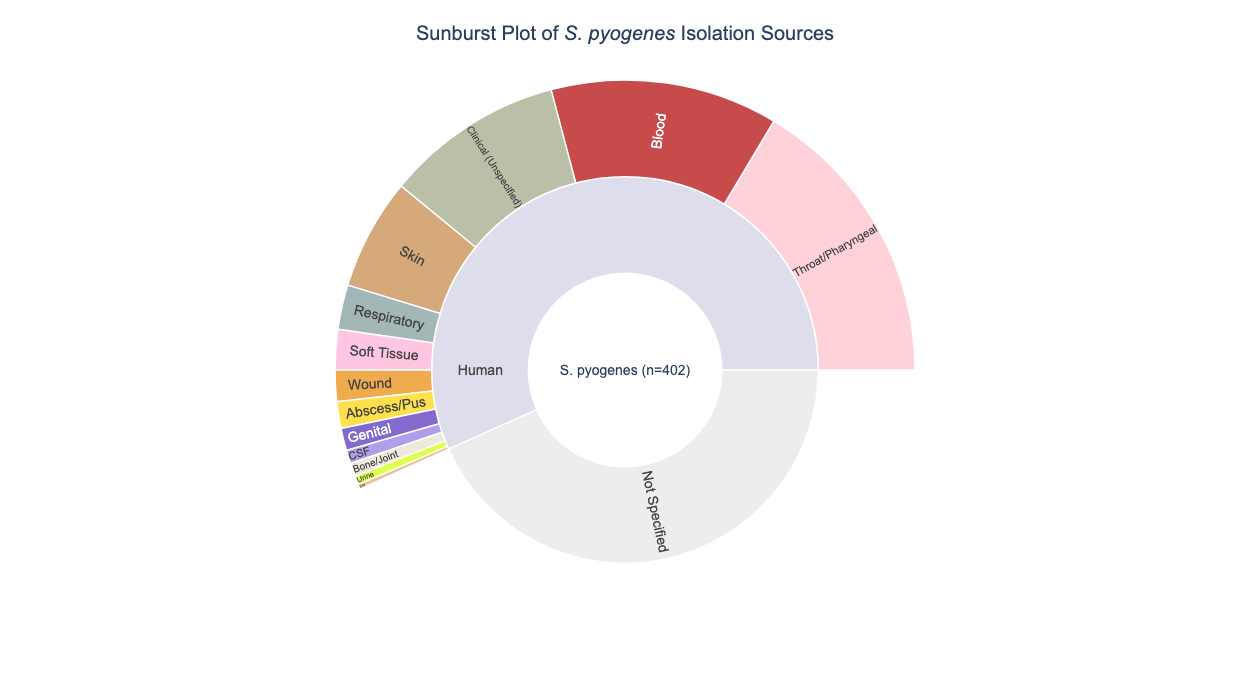

In [37]:
import pandas as pd
import plotly.graph_objects as go

# ── Load & normalize ──
df = mash_scrubbed_metadata_clst
df['iso_raw'] = df['isolation_source'].fillna('').str.strip().str.lower()


# ── Categorize isolation sources into (host, source) hierarchy ──
def categorize(raw):
    r = raw.strip().lower()

    not_spec = [
        '', 'not provided', 'not available: to be reported later',
        'not collected', 'not available: not collected', 'missing'
    ]
    if r in not_spec:
        return ('Not Specified', 'Not Specified')

    if r.startswith('blood') or r in ['peripheral blood', 'venous', 'blood culture']:
        return ('Human', 'Blood')

    if any(k in r for k in ['throat', 'pharyn', 'oropharyn']):
        return ('Human', 'Throat/Pharyngeal')

    if any(k in r for k in ['skin', 'impetigo', 'facial cutaneous', 'foot lesion']):
        return ('Human', 'Skin')

    if 'wound' in r:
        return ('Human', 'Wound')

    if any(k in r for k in ['soft tissue', 'deep tissue', 'tissue',
                             'cellulitis', 'necrotizing fasciitis']):
        return ('Human', 'Soft Tissue')

    if any(k in r for k in ['abscess', 'pus', 'cerebral abscess']):
        return ('Human', 'Abscess/Pus')

    if any(k in r for k in ['respiratory', 'endotracheal', 'sputum',
                             'pleural', 'plevra']):
        return ('Human', 'Respiratory')

    if 'csf' in r or 'cerebrospinal' in r or 'meningitis' in r:
        return ('Human', 'CSF')

    if any(k in r for k in ['genital', 'vaginal', 'vulva', 'perianal', 'anusitis']):
        return ('Human', 'Genital')

    if any(k in r for k in ['bone', 'knee', 'tendon']):
        return ('Human', 'Bone/Joint')

    if 'urine' in r:
        return ('Human', 'Urine')

    if 'otitis' in r:
        return ('Human', 'Ear')

    if any(k in r for k in ['clinical', 'normally sterile', 'invasive', 'hospital',
                             'human', 'patient', 'stss', 'toxic-shock',
                             'glomerulonephritis', 'scarlet fever', 'secretion']):
        return ('Human', 'Clinical (Unspecified)')

    return ('Human', 'Other')


cats = df['iso_raw'].apply(categorize)
df['host_cat'] = [c[0] for c in cats]
df['source_cat'] = [c[1] for c in cats]


# ── Color maps ──
host_colors = {
    'Human':         'rgba(180, 180, 210, 0.45)',
    'Not Specified': 'rgba(200, 200, 200, 0.45)',
}

source_colors = {
    'Blood':                  '#b00000',
    'Throat/Pharyngeal':      '#ffc0cb',
    'Skin':                   '#c68642',
    'Respiratory':            '#7d999a',
    'Wound':                  '#e98804',
    'Abscess/Pus':            '#ffd400',
    'Genital':                '#502cbc',
    'CSF':                    '#9076e0',
    'Bone/Joint':             '#e9e0d0',
    'Urine':                  '#cfff04',
    'Ear':                    '#e0ac69',
    'Soft Tissue':            '#ffaed7',
    'Clinical (Unspecified)': '#9ca683',
    'Other':                  '#cccccc',
    'Not Specified':          'rgba(200, 200, 200, 0.65)',
}


# ── Build sunburst arrays ──
root_label = f'S. pyogenes (n={len(df)})'
labels  = [root_label]
parents = ['']
values  = [len(df)]
colors  = ['rgba(255,255,255,0)']

for host in ['Human', 'Not Specified']:
    count = (df['host_cat'] == host).sum()
    if count > 0:
        labels.append(host)
        parents.append(root_label)
        values.append(count)
        colors.append(host_colors[host])

for host in ['Human', 'Not Specified']:
    sub = df[df['host_cat'] == host]
    for src, cnt in sub['source_cat'].value_counts().items():
        if src == 'Not Specified' and host == 'Not Specified':
            continue
        labels.append(src)
        parents.append(host)
        values.append(cnt)
        colors.append(source_colors.get(src, '#cccccc'))


# ── Plot ──
fig = go.Figure(go.Sunburst(
    labels=labels,
    parents=parents,
    values=values,
    branchvalues='total',
    marker=dict(
        colors=colors,
        line=dict(color='white', width=1.5),
    ),
    textfont=dict(size=14),
    insidetextorientation='radial',
    hovertemplate=(
        '<b>%{label}</b><br>'
        'Count: %{value}<br>'
        'Percent: %{percentRoot:.1%}'
        '<extra></extra>'
    ),
))

fig.update_layout(
    title=dict(
        text='Sunburst Plot of <i>S. pyogenes</i> Isolation Sources',
        font=dict(size=20),
        x=0.5,
    ),
    width=900,
    height=700,
    margin=dict(t=80, l=40, r=40, b=40),
    font=dict(family='Arial'),
)

fig.write_html(
    'spyo_isolation_sunburst.html',
    include_plotlyjs='cdn',
)

fig.show()

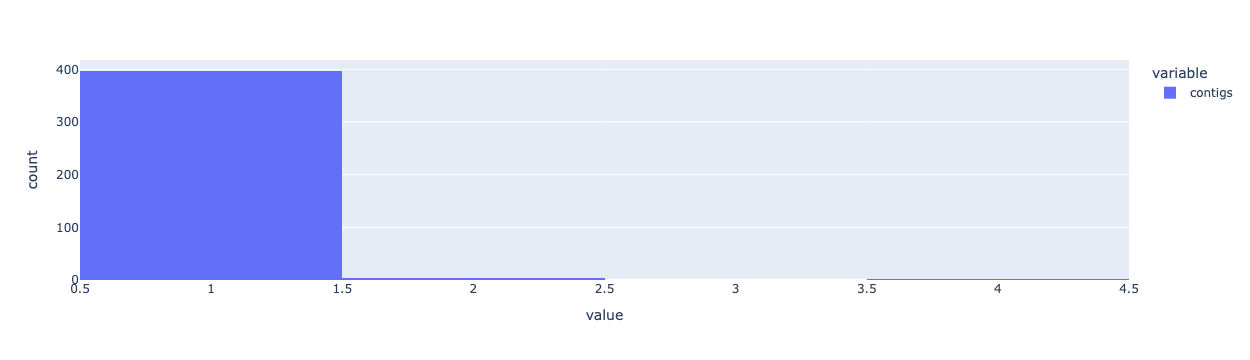

In [41]:
px.histogram(
    mash_scrubbed_metadata_clst.
    contigs.
    astype(int)
)

Coverage: 188/402 -> 334/402

country_merged
USA                    99
None                   68
Iceland                49
United Kingdom         34
Italy                  32
Australia              27
Japan                  11
India                  10
France                  9
Fiji                    9
Poland                  8
Finland                 8
Brazil                  7
Canada                  5
China                   5
New Zealand             4
Kenya                   3
Germany                 2
Turkey                  2
Russia                  2
Netherlands             1
Saudi Arabia            1
Israel                  1
Taiwan                  1
Ethiopia                1
Trinidad and Tobago     1
Hong Kong               1
Belgium                 1


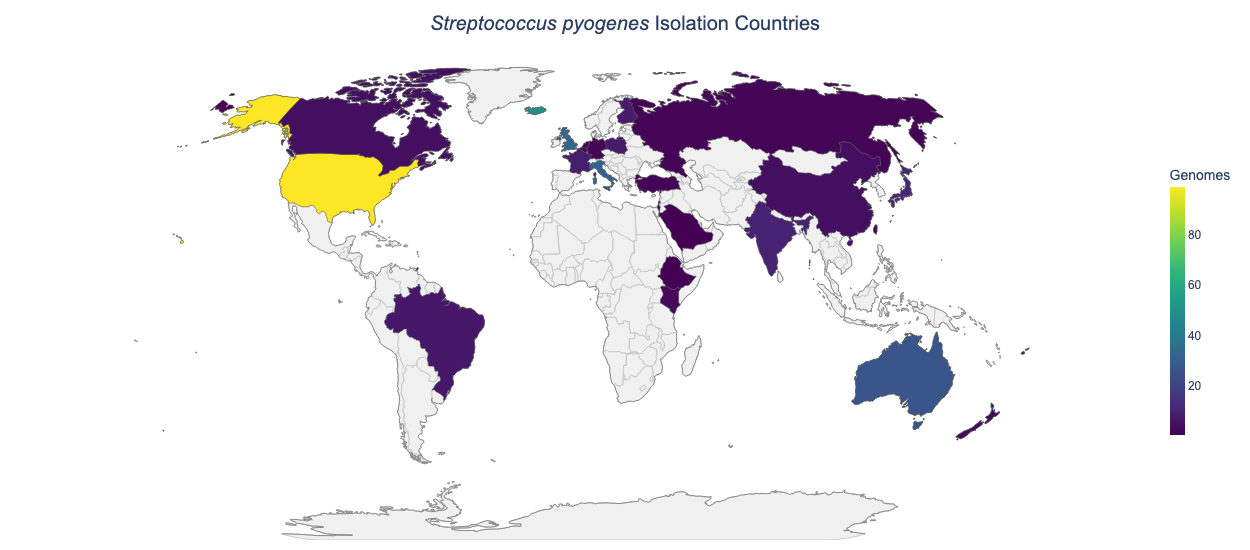

In [43]:
import pandas as pd
import plotly.graph_objects as go

df = mash_scrubbed_metadata_clst

# ── Extract country from geographic_location ──
def parse_country_from_geo(val):
    if pd.isna(val):
        return None
    v = val.strip()
    if v.lower() in ['not applicable', 'not collected', 'missing', '']:
        return None

    # Extract the country part (before ":" or the whole string)
    country_part = v.split(':')[0].strip()

    # Manual mapping for messy entries
    geo_to_country = {
        'USA':              'USA',
        'United States':    'USA',
        'Pennsilvania':     'USA',
        'Pennsylvania':     'USA',
        'Texas':            'USA',
        'Ontario':          'Canada',
        'Australia':        'Australia',
        'United Kingdom':   'United Kingdom',
        'Iceland':          'Iceland',
        'Italy':            'Italy',
        'Fiji':             'Fiji',
        'Finland':          'Finland',
        'Brazil':           'Brazil',
        'India':            'India',
        'Japan':            'Japan',
        'France':           'France',
        'China':            'China',
        'Canada':           'Canada',
        'New Zealand':      'New Zealand',
        'Kenya':            'Kenya',
        'Russia':           'Russia',
        'Poland':           'Poland',
        'Turkey':           'Turkey',
        'Germany':          'Germany',
        'Belgium':          'Belgium',
        'Hong Kong':        'Hong Kong',
        'Taiwan':           'Taiwan',
        'Saudi Arabia':     'Saudi Arabia',
        'Trinidad and Tobago': 'Trinidad and Tobago',
        'Ethiopia':         'Ethiopia',
        'Israel':           'Israel',
        'Netherlands':      'Netherlands',
    }

    # Check for "Tainan Provincial Hospital ROC"
    if 'ROC' in v or 'Tainan' in v:
        return 'Taiwan'

    return geo_to_country.get(country_part, None)


# ── Merge: prefer isolation_country, fill gaps with geographic_location ──
df['country_merged'] = df['isolation_country'].copy()

mask = df['country_merged'].isna()
df.loc[mask, 'country_merged'] = df.loc[mask, 'geographic_location'].apply(parse_country_from_geo)

# Report coverage
orig = df['isolation_country'].notna().sum()
merged = df['country_merged'].notna().sum()
print(f'Coverage: {orig}/402 -> {merged}/402')
print()
print(df['country_merged'].value_counts(dropna=False).to_string())

# ── Build choropleth ──
country_counts = df['country_merged'].dropna().value_counts().reset_index()
country_counts.columns = ['country', 'count']

name_to_iso3 = {
    'USA':                  'USA',
    'Australia':            'AUS',
    'United Kingdom':       'GBR',
    'India':                'IND',
    'Fiji':                 'FJI',
    'Japan':                'JPN',
    'France':               'FRA',
    'Finland':              'FIN',
    'Brazil':               'BRA',
    'China':                'CHN',
    'Canada':               'CAN',
    'New Zealand':          'NZL',
    'Iceland':              'ISL',
    'Kenya':                'KEN',
    'Russia':               'RUS',
    'Taiwan':               'TWN',
    'Hong Kong':            'HKG',
    'Italy':                'ITA',
    'Saudi Arabia':         'SAU',
    'Trinidad and Tobago':  'TTO',
    'Ethiopia':             'ETH',
    'Israel':               'ISR',
    'Netherlands':          'NLD',
    'Poland':               'POL',
    'Turkey':               'TUR',
    'Germany':              'DEU',
    'Belgium':              'BEL',
}

country_counts['iso3'] = country_counts['country'].map(name_to_iso3)

fig = go.Figure(go.Choropleth(
    locations=country_counts['iso3'],
    z=country_counts['count'],
    text=country_counts['country'],
    colorscale='Viridis',
    reversescale=False,
    marker_line_color='#555',
    marker_line_width=0.5,
    colorbar=dict(
        title=dict(text='Genomes', font=dict(size=14)),
        thickness=15,
        len=0.6,
        tickfont=dict(size=12),
    ),
    hovertemplate='<b>%{text}</b><br>Genomes: %{z}<extra></extra>',
))

fig.update_geos(
    showframe=False,
    showcoastlines=True,
    coastlinecolor='#888',
    projection_type='natural earth',
    landcolor='#f0f0f0',
    showocean=True,
    oceancolor='white',
    showlakes=False,
    showcountries=True,
    countrycolor='#ccc',
)

fig.update_layout(
    title=dict(
        text='<i>Streptococcus pyogenes</i> Isolation Countries',
        font=dict(size=20),
        x=0.5,
    ),
    width=1000,
    height=550,
    margin=dict(t=60, l=10, r=10, b=10),
    font=dict(family='Arial'),
)

fig.write_html(
    'spyo_isolation_countries.html',
    include_plotlyjs='cdn',
)

fig.show()

# Save Mash-scrubbed `summary` and `metadata`

In [44]:
mash_scrubbed_metadata_clst.shape

(402, 131)

In [45]:
filepath = UNIFIED_METADATA.split('unified_genome_metadata.csv')[0]
filepath = os.path.join(filepath, 'mash_scrubbed_genome_metadata.csv')
filepath

'/mnt/craig/pan_phylon/S_pyogenes/metadata/mash_scrubbed_genome_metadata.csv'

In [47]:
mash_scrubbed_metadata_clst.reset_index().to_csv(filepath)

## Save Mash results

In [48]:
filepath = filepath.split('mash_scrubbed_genome_metadata.csv')[0]
filepath = os.path.join(filepath, 'df_mash_square.csv')
filepath

'/mnt/craig/pan_phylon/S_pyogenes/metadata/df_mash_square.csv'

In [49]:
df_mash_square.to_csv(filepath)

In [50]:
filepath = filepath.split('df_mash_square.csv')[0]
filepath = os.path.join(filepath, 'df_mash_corr_dist.csv')
filepath

'/mnt/craig/pan_phylon/S_pyogenes/metadata/df_mash_corr_dist.csv'

In [51]:
df_mash_corr_dist.to_csv(filepath)